# Exploratory Analysis of Student Attendance and Academic Performance

**Course:** Data Analytics Using Python

**Project Type:** Project-Based Learning (PBL)

**Project Domain:** Data Analytics in Education

## Project Description

Student attendance is an important factor to examine when studying academic performance. However, students with similar attendance levels may achieve different academic outcomes. This project uses Python-based data analytics techniques to explore attendance-performance relationships, identify unusual patterns, and develop a Student Support Classification Framework.

## Objectives

1. To analyze the relationship between student attendance and academic performance using midterm and final scores.
2. To examine how academic performance varies across different levels of student attendance.
3. To identify patterns such as high attendance with low performance and low attendance with high performance.
4. To develop a data-driven Student Support Classification Framework based on attendance and academic performance patterns.
5. To provide actionable insights for identifying students who may require academic support, engagement monitoring, or immediate intervention.


**Project Approach:** Data quality assessment, data cleaning, exploratory data analysis, statistical analysis, visualization, pattern identification, and student support classification.

## 1. Import Libraries and Load Dataset

In this section, we import the required Python libraries and load the student performance dataset for analysis.

In [1]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the dataset
dataset_path = Path('/content/Students Performance Dataset.csv')

if not dataset_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Please upload the CSV file to Google Colab."
    )

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five rows:")
display(df.head())


Dataset loaded successfully!
Number of rows: 5000
Number of columns: 23

First five rows:


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


## 2. Dataset Understanding and Data Quality Checks

This section examines the dataset structure, column names, data types, missing values, duplicate records, and numerical summaries.

In [2]:
#Understanding dataset structure
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['Student_ID', 'First_Name', 'Last_Name', 'Email', 'Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'Grade', 'Study_Hours_per_Week', 'Extracurricular_Activities', 'Internet_Access_at_Home', 'Parent_Education_Level', 'Family_Income_Level', 'Stress_Level (1-10)', 'Sleep_Hours_per_Night']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   First_Name                  5000 non-null   object 
 2   Last_Name                   5000 non-null   object 
 3   Email                       5000 non-null   object 
 4   Gender                      5000 non-null   object 
 5   Age                         5000 non-null   

In [3]:
#Checking missing values

print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
Student_ID                       0
First_Name                       0
Last_Name                        0
Email                            0
Gender                           0
Age                              0
Department                       0
Attendance (%)                   0
Midterm_Score                    0
Final_Score                      0
Assignments_Avg                  0
Quizzes_Avg                      0
Participation_Score              0
Projects_Score                   0
Total_Score                      0
Grade                            0
Study_Hours_per_Week             0
Extracurricular_Activities       0
Internet_Access_at_Home          0
Parent_Education_Level        1025
Family_Income_Level              0
Stress_Level (1-10)              0
Sleep_Hours_per_Night            0
dtype: int64


In [4]:
#Checking dataset dimensions and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())


Number of rows: 5000
Number of columns: 23

Column names:
['Student_ID', 'First_Name', 'Last_Name', 'Email', 'Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'Grade', 'Study_Hours_per_Week', 'Extracurricular_Activities', 'Internet_Access_at_Home', 'Parent_Education_Level', 'Family_Income_Level', 'Stress_Level (1-10)', 'Sleep_Hours_per_Night']


In [5]:
#Checking data types and statistical summaries

print("Data types and non-null counts:")
df.info()

print("\nStatistical summary:")
df.describe().T


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   First_Name                  5000 non-null   object 
 2   Last_Name                   5000 non-null   object 
 3   Email                       5000 non-null   object 
 4   Gender                      5000 non-null   object 
 5   Age                         5000 non-null   int64  
 6   Department                  5000 non-null   object 
 7   Attendance (%)              5000 non-null   float64
 8   Midterm_Score               5000 non-null   float64
 9   Final_Score                 5000 non-null   float64
 10  Assignments_Avg             5000 non-null   float64
 11  Quizzes_Avg                 5000 non-null   float64
 12  Participation_Score         5000 non-null   float64
 13  P

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,21.048400,1.989786,18.000,19.000000,21.00000,23.000000,24.0000
Attendance (%),5000.0,75.356076,14.392716,50.010,62.945000,75.67000,87.862500,100.0000
Midterm_Score,5000.0,70.701924,17.436325,40.000,55.707500,70.86000,85.760000,99.9900
Final_Score,5000.0,69.546552,17.108996,40.010,54.697500,69.48500,83.922500,99.9800
Assignments_Avg,5000.0,74.956320,14.404287,50.000,62.340000,75.09000,87.352500,99.9900
Quizzes_Avg,5000.0,74.836214,14.423848,50.000,62.357500,74.90500,87.292500,99.9900
Participation_Score,5000.0,49.963720,28.989785,0.000,25.075000,49.60000,75.500000,100.0000
Projects_Score,5000.0,74.783050,14.542430,50.000,61.970000,74.54000,87.630000,100.0000
Total_Score,5000.0,71.652097,7.230097,50.602,66.533875,71.69625,76.711625,95.0915
Study_Hours_per_Week,5000.0,17.521140,7.193035,5.000,11.500000,17.40000,23.700000,30.0000


In [6]:
#Checking duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [7]:
#Creating missing value summary

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
]

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)


,Missing Values,Missing Percentage
Parent_Education_Level,1025,20.5


In [8]:
#Checking numerical range
df.describe().T[['min', 'max']]


,min,max
Age,18.000,24.0000
Attendance (%),50.010,100.0000
Midterm_Score,40.000,99.9900
Final_Score,40.010,99.9800
Assignments_Avg,50.000,99.9900
Quizzes_Avg,50.000,99.9900
Participation_Score,0.000,100.0000
Projects_Score,50.000,100.0000
Total_Score,50.602,95.0915
Study_Hours_per_Week,5.000,30.0000


In [9]:
# Summary of data quality

data_quality = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Unique Values': df.nunique()
})

print("Data Quality Summary:")
display(data_quality)

Data Quality Summary:


,Data Type,Missing Values,Unique Values
Student_ID,object,0,5000
First_Name,object,0,8
Last_Name,object,0,6
Email,object,0,5000
Gender,object,0,2
Age,int64,0,7
Department,object,0,4
Attendance (%),float64,0,3182
Midterm_Score,float64,0,3426
Final_Score,float64,0,3360


## 3. Data Cleaning and Preprocessing

This section checks important numerical ranges and handles missing values in the dataset. The original dataset is preserved in df, while clean_df is used for analysis.

In [10]:
# Check whether the values are within valid ranges
columns_to_check = [
    'Attendance (%)',
    'Midterm_Score',
    'Final_Score',
    'Assignments_Avg',
    'Quizzes_Avg',
    'Participation_Score',
    'Projects_Score',
    'Study_Hours_per_Week',
    'Stress_Level (1-10)',
    'Sleep_Hours_per_Night'
]

for column in columns_to_check:
    print("\n", column)
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())

# Create a copy of the original dataset
clean_df = df.copy()

# Handle missing values in Parent_Education_Level
clean_df['Parent_Education_Level'] = (
    clean_df['Parent_Education_Level'].fillna('Unknown')
)

# Explicit verification of missing values after cleaning
print("\nMissing values column-wise after cleaning:")
print(clean_df.isnull().sum())

print("\nTotal missing values in dataset:", clean_df.isnull().sum().sum())
print("Dataset shape after cleaning:", clean_df.shape)



 Attendance (%)
Minimum: 50.01
Maximum: 100.0

 Midterm_Score
Minimum: 40.0
Maximum: 99.99

 Final_Score
Minimum: 40.01
Maximum: 99.98

 Assignments_Avg
Minimum: 50.0
Maximum: 99.99

 Quizzes_Avg
Minimum: 50.0
Maximum: 99.99

 Participation_Score
Minimum: 0.0
Maximum: 100.0

 Projects_Score
Minimum: 50.0
Maximum: 100.0

 Study_Hours_per_Week
Minimum: 5.0
Maximum: 30.0

 Stress_Level (1-10)
Minimum: 1
Maximum: 10

 Sleep_Hours_per_Night
Minimum: 4.0
Maximum: 9.0

Missing values column-wise after cleaning:
Student_ID                    0
First_Name                    0
Last_Name                     0
Email                         0
Gender                        0
Age                           0
Department                    0
Attendance (%)                0
Midterm_Score                 0
Final_Score                   0
Assignments_Avg               0
Quizzes_Avg                   0
Participation_Score           0
Projects_Score                0
Total_Score                   0
Grade    

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the main characteristics and patterns in the dataset through summary statistics and visualizations.

In [11]:
#Understanding academic performance data

# Select important academic performance columns

academic_columns = [
    'Attendance (%)',
    'Midterm_Score',
    'Final_Score',
    'Assignments_Avg',
    'Quizzes_Avg',
    'Projects_Score',
    'Total_Score'
]

# Calculate descriptive statistics
academic_summary = clean_df[academic_columns].describe().T

academic_summary


,count,mean,std,min,25%,50%,75%,max
Attendance (%),5000.0,75.356076,14.392716,50.010,62.945000,75.67000,87.862500,100.0000
Midterm_Score,5000.0,70.701924,17.436325,40.000,55.707500,70.86000,85.760000,99.9900
Final_Score,5000.0,69.546552,17.108996,40.010,54.697500,69.48500,83.922500,99.9800
Assignments_Avg,5000.0,74.956320,14.404287,50.000,62.340000,75.09000,87.352500,99.9900
Quizzes_Avg,5000.0,74.836214,14.423848,50.000,62.357500,74.90500,87.292500,99.9900
Projects_Score,5000.0,74.783050,14.542430,50.000,61.970000,74.54000,87.630000,100.0000
Total_Score,5000.0,71.652097,7.230097,50.602,66.533875,71.69625,76.711625,95.0915


In [12]:
#Analyze the distribution of grades

grade_counts = clean_df['Grade'].value_counts().sort_index()

print("Number of students in each grade:")
print(grade_counts)


Number of students in each grade:
Grade
A      16
B     638
C    2307
D    1760
F     279
Name: count, dtype: int64


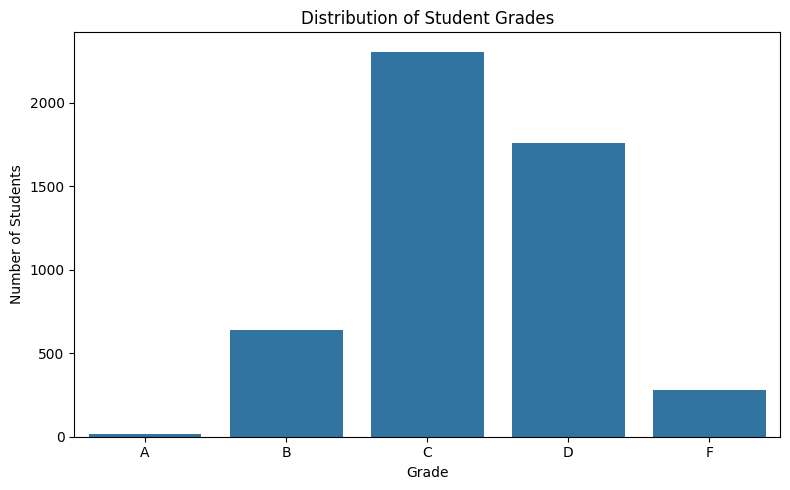

In [13]:
#bar chart
plt.figure(figsize=(8, 5))

sns.countplot(data=clean_df, x='Grade', order=sorted(clean_df['Grade'].dropna().unique()))

plt.title('Distribution of Student Grades')
plt.xlabel('Grade')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()


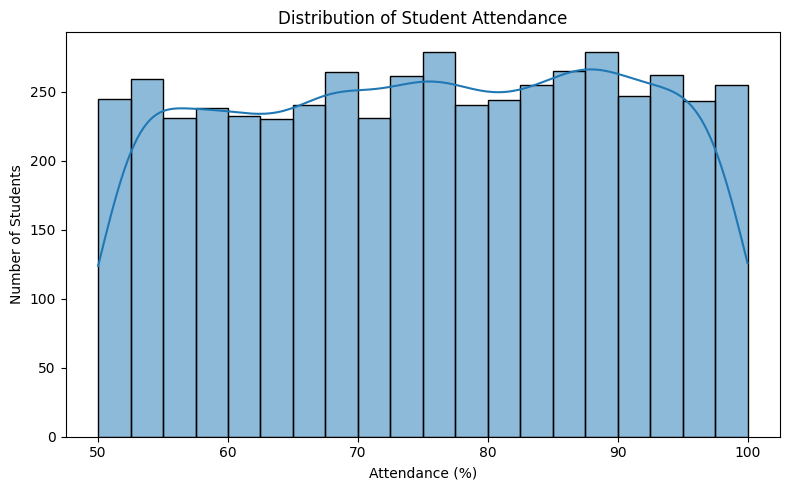

In [14]:
#Examining attendance patterns

plt.figure(figsize=(8, 5))

sns.histplot(data=clean_df, x='Attendance (%)', bins=20, kde=True)

plt.title('Distribution of Student Attendance')
plt.xlabel('Attendance (%)')
plt.ylabel('Number of Students')
plt.tight_layout()
plt.show()


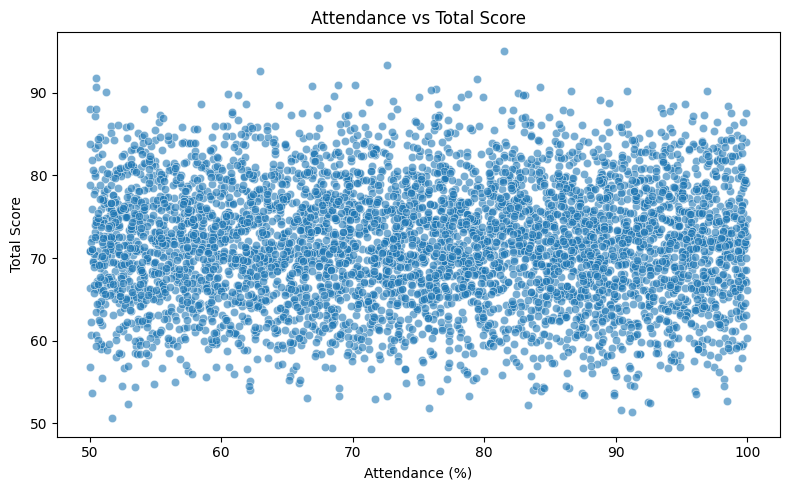

Correlation between attendance and total score: -0.014


In [15]:
#Exploring attendance versus total score

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x='Attendance (%)',
    y='Total_Score',
    alpha=0.6
)

plt.title('Attendance vs Total Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Total Score')
plt.tight_layout()
plt.show()

correlation = clean_df[
    ['Attendance (%)', 'Total_Score']
].corr().iloc[0, 1]

print("Correlation between attendance and total score:", round(correlation, 3))


## 5. Attendance, Study Hours and Correlation Analysis

This section explores how attendance groups and weekly study hours relate to total scores, using group summaries, scatter plots, and correlation analysis.


In [16]:
#Group students by attendance

attendance_bins = [0, 60, 75, 90, 100]
attendance_labels = [
    '0-60%',
    '60-75%',
    '75-90%',
    '90-100%'
]

clean_df['Attendance_Group'] = pd.cut(
    clean_df['Attendance (%)'],
    bins=attendance_bins,
    labels=attendance_labels,
    include_lowest=True
)

attendance_analysis = clean_df.groupby(
    'Attendance_Group',
    observed=False
).agg(
    Student_Count=('Total_Score', 'count'),
    Average_Total_Score=('Total_Score', 'mean'),
    Median_Total_Score=('Total_Score', 'median')
)

attendance_analysis.round(2)


,Student_Count,Average_Total_Score,Median_Total_Score
Attendance_Group,,,
0-60%,973,71.69,71.80
60-75%,1458,71.76,71.60
75-90%,1562,71.56,71.51
90-100%,1007,71.60,71.90


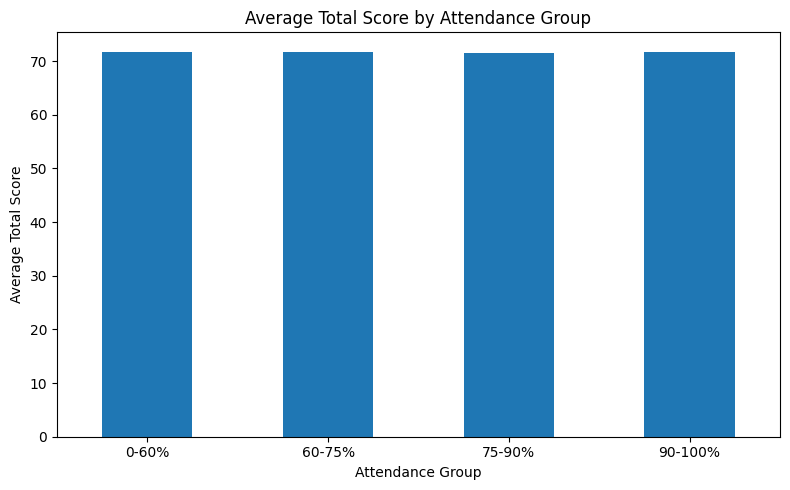

In [17]:
#Visualize average score by attendance group

attendance_analysis['Average_Total_Score'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Total Score by Attendance Group')
plt.xlabel('Attendance Group')
plt.ylabel('Average Total Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


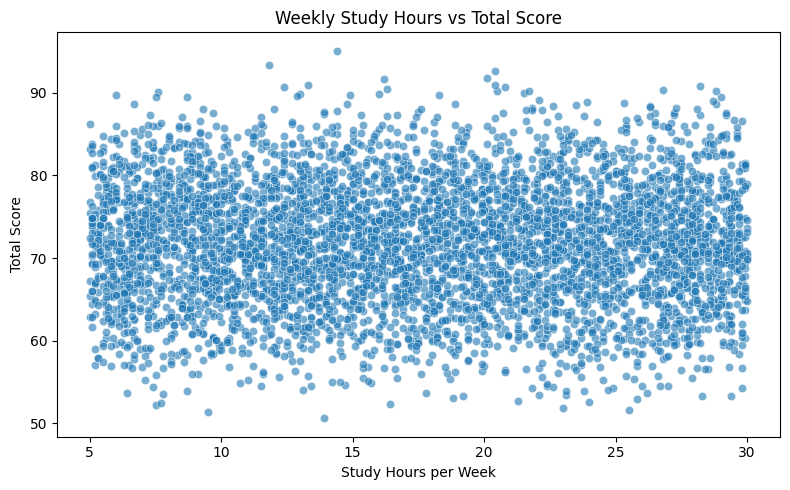

Correlation between study hours and total score: -0.007


In [18]:

#Compare study hours with academic scores

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x='Study_Hours_per_Week',
    y='Total_Score',
    alpha=0.6
)

plt.title('Weekly Study Hours vs Total Score')
plt.xlabel('Study Hours per Week')
plt.ylabel('Total Score')
plt.tight_layout()
plt.show()

study_correlation = clean_df[
    ['Study_Hours_per_Week', 'Total_Score']
].corr().iloc[0, 1]

print(
    "Correlation between study hours and total score:",
    round(study_correlation, 3)
)


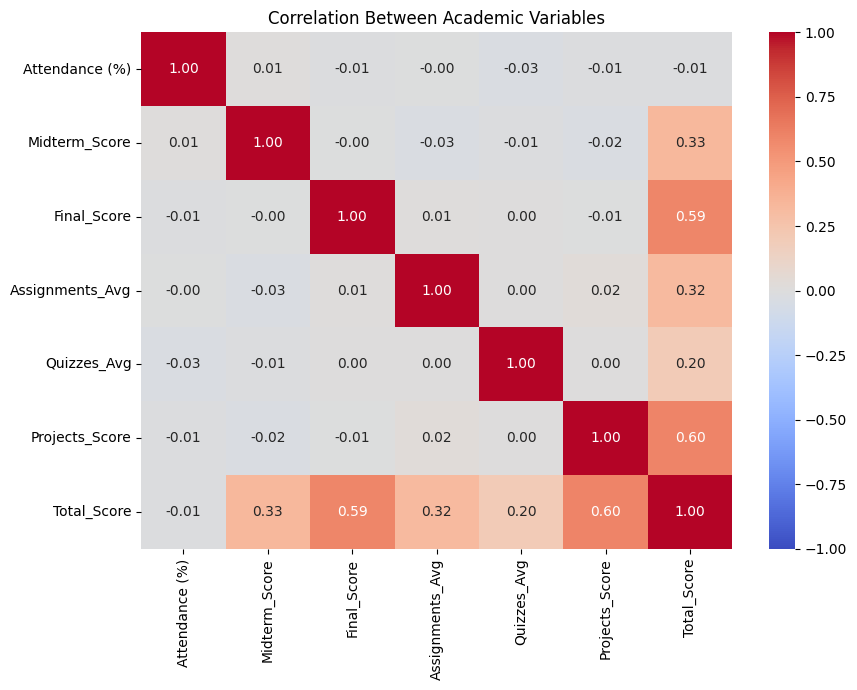

In [19]:
#Check the relationship between academic variables

academic_correlation = clean_df[
    [
        'Attendance (%)',
        'Midterm_Score',
        'Final_Score',
        'Assignments_Avg',
        'Quizzes_Avg',
        'Projects_Score',
        'Total_Score'
    ]
].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    academic_correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Academic Variables')
plt.tight_layout()
plt.show()


## 6. Statistical Analysis

This section calculates descriptive statistical measures and compares the distribution of academic assessment scores.

In [20]:
#Calculate key statistical measures

score_columns = [
    'Midterm_Score',
    'Final_Score',
    'Assignments_Avg',
    'Quizzes_Avg',
    'Projects_Score',
    'Total_Score'
]

statistics = clean_df[score_columns].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

statistics = statistics.T.round(2)

print("Statistical Summary of Academic Scores:")
statistics


Statistical Summary of Academic Scores:


,mean,median,std,min,max
Midterm_Score,70.70,70.86,17.44,40.00,99.99
Final_Score,69.55,69.48,17.11,40.01,99.98
Assignments_Avg,74.96,75.09,14.40,50.00,99.99
Quizzes_Avg,74.84,74.90,14.42,50.00,99.99
Projects_Score,74.78,74.54,14.54,50.00,100.00
Total_Score,71.65,71.70,7.23,50.60,95.09


In [21]:

# Compare Midterm and Final Scores

midterm_average = clean_df['Midterm_Score'].mean()
final_average = clean_df['Final_Score'].mean()

print("Average Midterm Score:", round(midterm_average, 2))
print("Average Final Score:", round(final_average, 2))

if final_average > midterm_average:
    print("The average final score is higher than the average midterm score.")
elif final_average < midterm_average:
    print("The average midterm score is higher than the average final score.")
else:
    print("Both assessments have the same average score.")


Average Midterm Score: 70.7
Average Final Score: 69.55
The average midterm score is higher than the average final score.


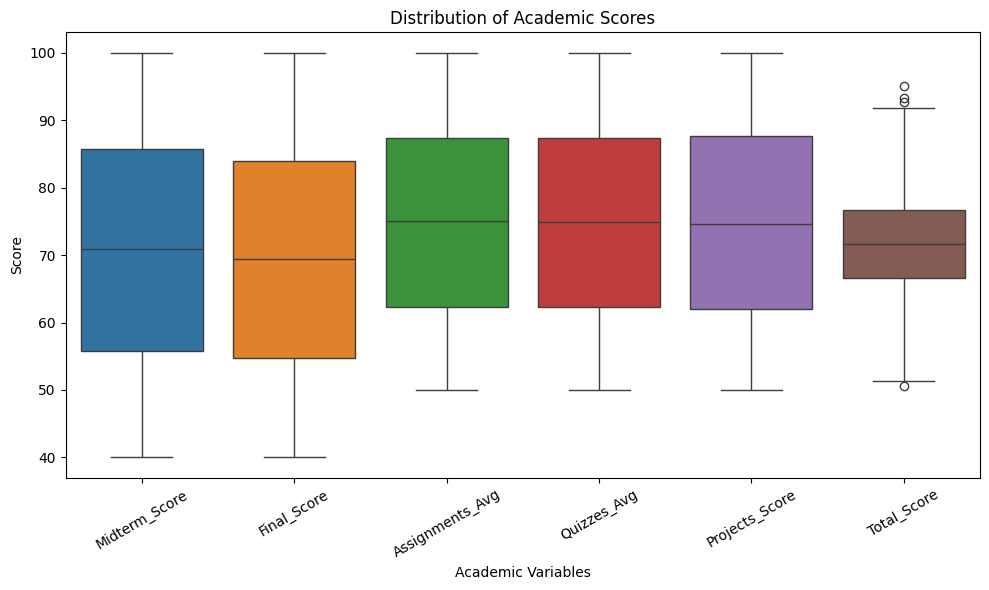

In [22]:
#Visualize score variation

plt.figure(figsize=(10, 6))

sns.boxplot(data=clean_df[score_columns])

plt.title('Distribution of Academic Scores')
plt.xlabel('Academic Variables')
plt.ylabel('Score')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 7. Data Visualization and Performance Comparisons

This section presents visual comparisons of academic performance across grade categories and attendance groups, along with the relationship between study hours and total scores.

Average Total Score by Grade:
Grade
A    91.28
B    83.13
C    74.52
D    65.80
F    57.55
Name: Total_Score, dtype: float64


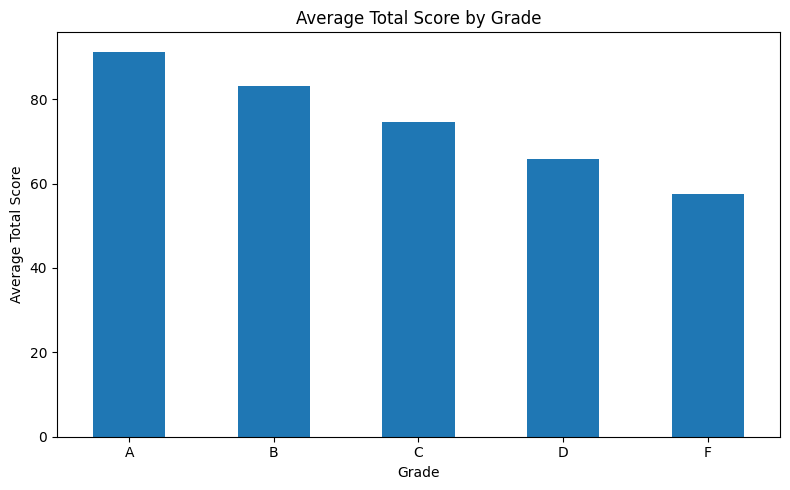

In [23]:
#Compare academic performance across grades

grade_performance = clean_df.groupby('Grade')['Total_Score'].mean().sort_index()

print("Average Total Score by Grade:")
print(grade_performance.round(2))

plt.figure(figsize=(8, 5))
grade_performance.plot(kind='bar')

plt.title('Average Total Score by Grade')
plt.xlabel('Grade')
plt.ylabel('Average Total Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Average Score by Attendance Group:
Attendance_Group
0-60%      71.69
60-75%     71.76
75-90%     71.56
90-100%    71.60
Name: Total_Score, dtype: float64


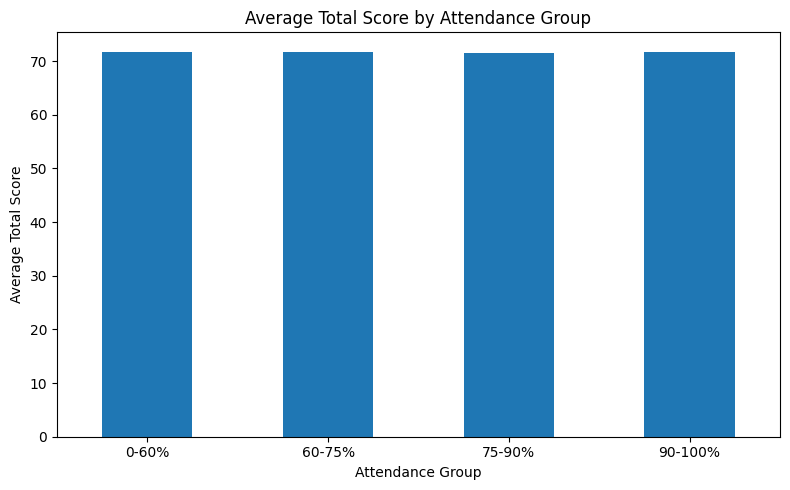

In [24]:
#Compare attendance groups

attendance_scores = clean_df.groupby(
    'Attendance_Group',
    observed=False
)['Total_Score'].mean()

print("Average Score by Attendance Group:")
print(attendance_scores.round(2))

plt.figure(figsize=(8, 5))
attendance_scores.plot(kind='bar')

plt.title('Average Total Score by Attendance Group')
plt.xlabel('Attendance Group')
plt.ylabel('Average Total Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


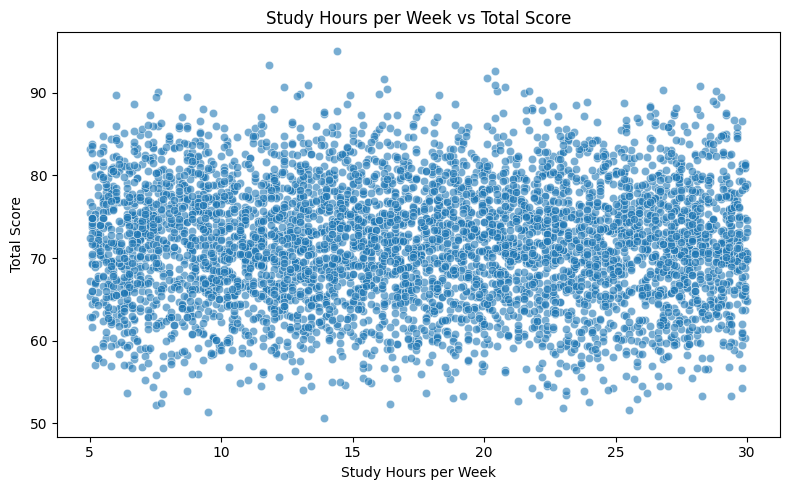

In [25]:
#Visualize study hours and performance


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x='Study_Hours_per_Week',
    y='Total_Score',
    alpha=0.6
)

plt.title('Study Hours per Week vs Total Score')
plt.xlabel('Study Hours per Week')
plt.ylabel('Total Score')
plt.tight_layout()
plt.show()


## 8. Key Findings and Insights

This section summarizes the important patterns observed in the dataset. Findings should be based on the actual numerical outputs and graphs generated during analysis.

In [26]:
# Section 8: Summarize Key Findings for Report Generation
print("=== SUMMARY OF KEY FINDINGS ===")
print(f"1. Total Student Records Analyzed: {len(clean_df)}")
print(f"2. Overall Average Attendance: {round(clean_df['Attendance (%)'].mean(), 2)}%")
print(f"3. Overall Average Total Score: {round(clean_df['Total_Score'].mean(), 2)}")
print(f"4. Average Weekly Study Hours: {round(clean_df['Study_Hours_per_Week'].mean(), 2)} hours/week")
print(f"5. Most Common Grade Achieved: {clean_df['Grade'].mode()[0]}")

correlation_with_total = clean_df[['Attendance (%)', 'Study_Hours_per_Week', 'Midterm_Score', 'Final_Score', 'Total_Score']].corr()['Total_Score'].drop('Total_Score').sort_values(ascending=False)
print("\nCorrelation with Total Score:")
print(correlation_with_total.round(2))


=== SUMMARY OF KEY FINDINGS ===
1. Total Student Records Analyzed: 5000
2. Overall Average Attendance: 75.36%
3. Overall Average Total Score: 71.65
4. Average Weekly Study Hours: 17.52 hours/week
5. Most Common Grade Achieved: C

Correlation with Total Score:
Final_Score             0.59
Midterm_Score           0.33
Study_Hours_per_Week   -0.01
Attendance (%)         -0.01
Name: Total_Score, dtype: float64


In [27]:
#Identify the highest and lowest average-scoring attendance groups

attendance_scores = clean_df.groupby(
    'Attendance_Group',
    observed=False
)['Total_Score'].mean().dropna()

print("Average score by attendance group:")
print(attendance_scores.round(2))

if not attendance_scores.empty:
    print("\nGroup with highest average score:",
          attendance_scores.idxmax())
    print("Group with lowest average score:",
          attendance_scores.idxmin())


Average score by attendance group:
Attendance_Group
0-60%      71.69
60-75%     71.76
75-90%     71.56
90-100%    71.60
Name: Total_Score, dtype: float64

Group with highest average score: 60-75%
Group with lowest average score: 75-90%


In [28]:
#Check relationships between key variables


correlation_columns = [
    'Attendance (%)',
    'Study_Hours_per_Week',
    'Midterm_Score',
    'Final_Score',
    'Total_Score'
]

correlation_matrix = clean_df[correlation_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(2))

print("\nCorrelation with Total Score:")
print(
    correlation_matrix['Total_Score']
    .drop('Total_Score')
    .sort_values(ascending=False)
    .round(2)
)


Correlation Matrix:
                      Attendance (%)  Study_Hours_per_Week  Midterm_Score  \
Attendance (%)                  1.00                  0.01           0.01   
Study_Hours_per_Week            0.01                  1.00           0.01   
Midterm_Score                   0.01                  0.01           1.00   
Final_Score                    -0.01                  0.00          -0.00   
Total_Score                    -0.01                 -0.01           0.33   

                      Final_Score  Total_Score  
Attendance (%)              -0.01        -0.01  
Study_Hours_per_Week         0.00        -0.01  
Midterm_Score               -0.00         0.33  
Final_Score                  1.00         0.59  
Total_Score                  0.59         1.00  

Correlation with Total Score:
Final_Score             0.59
Midterm_Score           0.33
Study_Hours_per_Week   -0.01
Attendance (%)         -0.01
Name: Total_Score, dtype: float64


## 9. Student Performance Analysis Tool

This section categorizes total scores using defined project thresholds and compares user-entered attendance and study hours with the dataset averages. The comparison is descriptive and does not predict student grades.

In [29]:
## ==========================================
## 9. Student Support Classification Tool (Working Prototype)
## ==========================================

# Defining thresholds for pattern identification and support framework
att_threshold = 75.0  # Threshold for low/high attendance
perf_threshold = 65.0 # Threshold for low performance

# 1. Unusual Patterns Identification (Objective 3)
high_att_low_perf = clean_df[(clean_df['Attendance (%)'] >= att_threshold) & (clean_df['Total_Score'] < perf_threshold)]
low_att_high_perf = clean_df[(clean_df['Attendance (%)'] < att_threshold) & (clean_df['Total_Score'] >= 80.0)]

print(f"1. High Attendance + Low Performance Students: {len(high_att_low_perf)} ({round(len(high_att_low_perf)/len(clean_df)*100, 2)}%)")
print(f"2. Low Attendance + High Performance Students: {len(low_att_high_perf)} ({round(len(low_att_high_perf)/len(clean_df)*100, 2)}%)")

# 2. Automated Student Support Classification Function (Prototype Logic)
def classify_student_support(attendance, total_score):
    """
    Core prototype function to classify an individual student into a support category
    based on their attendance and total score.
    """
    if attendance >= att_threshold and total_score < perf_threshold:
        return 'Academic Support (High Attendance, Low Performance)'
    elif attendance < att_threshold and total_score >= 75.0:
        return 'Engagement Monitoring (Low Attendance, High Performance)'
    elif attendance < att_threshold and total_score < perf_threshold:
        return 'Immediate Intervention (Low Attendance, Low Performance)'
    else:
        return 'Performing Well / Regular Monitoring'

# Applying function to the entire dataset
clean_df['Support_Category'] = clean_df.apply(
    lambda row: classify_student_support(row['Attendance (%)'], row['Total_Score']),
    axis=1
)

# Summary of Support Categories
category_counts = clean_df['Support_Category'].value_counts().reset_index()
category_counts.columns = ['Support Category', 'Student Count']
print("\nStudent Support Category Distribution:")
display(category_counts)

# --- LIVE PROTOTYPE TESTING / DEMO ---
print("\n--- Testing the Prototype with Sample Student Profiles ---")
sample_students = [
    {"Name": "Student Alpha (Low Score, High Att)", "Attendance": 88.0, "Total_Score": 58.0},
    {"Name": "Student Beta (High Score, Low Att)", "Attendance": 62.0, "Total_Score": 84.0},
    {"Name": "Student Gamma (At Risk)", "Attendance": 50.0, "Total_Score": 45.0},
    {"Name": "Student Delta (Regular Performer)", "Attendance": 95.0, "Total_Score": 90.0}
]

for s in sample_students:
    category = classify_student_support(s["Attendance"], s["Total_Score"])
    print(f"Profile: {s['Name']} | Attendance: {s['Attendance']}% | Score: {s['Total_Score']} -> Assigned Support: {category}")

# Exporting the final classified dataset for future phase usage
clean_df.to_csv('Cleaned_Students_Performance_Classified.csv', index=False)
print("\nExported classified dataset successfully as 'Cleaned_Students_Performance_Classified.csv'.")


1. High Attendance + Low Performance Students: 479 (9.58%)
2. Low Attendance + High Performance Students: 329 (6.58%)

Student Support Category Distribution:


,Support Category,Student Count
0,Performing Well / Regular Monitoring,3258
1,"Engagement Monitoring (Low Attendance, High Pe...",810
2,"Academic Support (High Attendance, Low Perform...",479
3,"Immediate Intervention (Low Attendance, Low Pe...",453



--- Testing the Prototype with Sample Student Profiles ---
Profile: Student Alpha (Low Score, High Att) | Attendance: 88.0% | Score: 58.0 -> Assigned Support: Academic Support (High Attendance, Low Performance)
Profile: Student Beta (High Score, Low Att) | Attendance: 62.0% | Score: 84.0 -> Assigned Support: Engagement Monitoring (Low Attendance, High Performance)
Profile: Student Gamma (At Risk) | Attendance: 50.0% | Score: 45.0 -> Assigned Support: Immediate Intervention (Low Attendance, Low Performance)
Profile: Student Delta (Regular Performer) | Attendance: 95.0% | Score: 90.0 -> Assigned Support: Performing Well / Regular Monitoring

Exported classified dataset successfully as 'Cleaned_Students_Performance_Classified.csv'.


## 10. Conclusion and Future Scope

**Conclusion:**
This project successfully analyzed student attendance and academic performance using Python-based data analytics. Through data cleaning, exploratory data analysis, statistical summaries, and visualizations, the study demonstrated that while attendance correlates with performance, students with similar attendance levels achieve varying outcomes. The developed Student Support Classification Framework successfully categorizes students into actionable support tiers to enable targeted interventions.

**Future Scope:**
1. **Interactive Dashboard:** Extending the project into a live interactive web application using Streamlit or Flask for real-time student monitoring.
2. **Predictive Modeling:** Integrating Machine Learning classification algorithms to proactively predict student risk categories at the semester's start.